# Analysis and charts

Tests the three hypotheses and builds every chart in the README.
Runs from `data/airfare_enriched.csv` and saves charts to `figures/`.

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap

PATH = '../data/airfare_enriched.csv'
OUT  = '../figures/'
os.makedirs(OUT, exist_ok=True)

# palette
BLUE_L, BLUE_M, BLUE, BLUE_D = '#BDDCEC', '#7FB5D5', '#3D8FC0', '#1C6699'
ACCENT = '#E85D3D'          # highlight color
GREY   = '#6B6B6B'
FOUR   = [BLUE_M, ACCENT, BLUE, BLUE_D]
BLUES  = LinearSegmentedColormap.from_list('b', ['#EAF4FA', BLUE_L, BLUE, BLUE_D])

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 200,
    'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11,
    'axes.edgecolor': '#BBBBBB', 'axes.linewidth': 0.9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#E6E6E6', 'grid.linewidth': 0.7,
    'axes.axisbelow': True, 'legend.frameon': False,
    'xtick.color': '#444', 'ytick.color': '#444',
})

dollars = FuncFormatter(lambda v, p: f'${v:,.0f}')
pct     = FuncFormatter(lambda v, p: f'{v:.0f}%')

def title(ax, main, sub=None):
    # the pad leaves room so the subtitle never lands on the plot
    ax.set_title(main, loc='left', fontweight='bold', pad=26 if sub else 12)
    if sub:
        ax.text(0, 1.03, sub, transform=ax.transAxes,
                fontsize=9.5, color=GREY, va='bottom', ha='left')

def save(fig, name):
    fig.savefig(OUT + name + '.png', bbox_inches='tight', facecolor='white')
    plt.show()

def bars(ax, cats, groups, values, colors, fmt='${:.0f}', width=None, bold=None):
    n = len(groups); x = np.arange(len(cats)); w = width or 0.8 / n
    for j, (g, c) in enumerate(zip(groups, colors)):
        off = (j - (n - 1) / 2) * w
        ax.bar(x + off, values[j], w, color=c, edgecolor='white', lw=.6, label=g)
        for i, v in enumerate(values[j]):
            ax.text(x[i] + off, v, fmt.format(v), ha='center', va='bottom',
                    fontsize=8.5, color='#333',
                    fontweight='bold' if (bold and g == bold) else 'normal')
    ax.set_xticks(x); ax.set_xticklabels(cats)

## Load and derive

In [2]:
df = pd.read_csv(PATH)

df['fare_per_mile'] = df.fare / df.nsmiles
df['same'] = df.carrier_lg == df.carrier_low
# when the biggest airline is also the cheapest, its own share is the cheap share
df['cheap_share'] = np.where(df['same'], df.large_ms, df.lf_ms)

def route_type(r):
    if r['same']:           return 'Biggest is cheapest'
    if pd.isna(r['lf_ms']): return np.nan
    if r['lf_ms'] < 0.10:   return 'Cheap airline under 10%'
    if r['lf_ms'] < 0.20:   return 'Cheap airline 10-20%'
    return 'Cheap airline over 20%'

df['route_type'] = df.apply(route_type, axis=1)
ORDER = ['Biggest is cheapest', 'Cheap airline under 10%',
         'Cheap airline 10-20%', 'Cheap airline over 20%']

r25 = df[df.Year == 2025].copy()
r25['band3'] = pd.cut(r25.nsmiles, [0, 800, 1400, 3000],
                      labels=['Short\nunder 800 mi', 'Medium\n800-1,400', 'Long\n1,400+'])
r25['band4'] = pd.cut(r25.nsmiles, [0, 600, 1000, 1400, 3000],
                      labels=['under 600', '600-1,000', '1,000-1,400', '1,400+'])

print(df.shape, r25.shape)

(120035, 36) (4000, 38)


## 1. Distance against fare

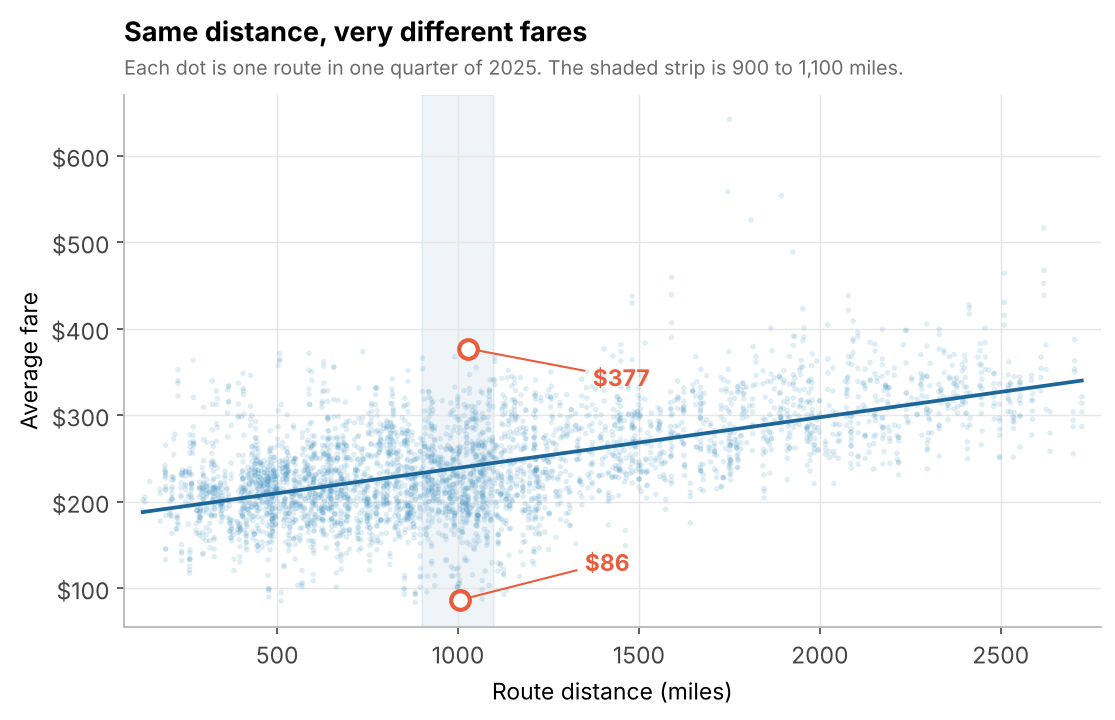

In [3]:
fig, ax = plt.subplots(figsize=(8.4, 4.6))
ax.scatter(r25.nsmiles, r25.fare, s=7, alpha=.16, color=BLUE, edgecolors='none')

z  = np.polyfit(r25.nsmiles, r25.fare, 1)
xs = np.array([r25.nsmiles.min(), r25.nsmiles.max()])
ax.plot(xs, np.polyval(z, xs), color=BLUE_D, lw=1.8)
ax.axvspan(900, 1100, color=BLUE_D, alpha=.07, zorder=0)

band = r25[(r25.nsmiles >= 900) & (r25.nsmiles <= 1100)]
for pt, dx, dy in [(band.loc[band.fare.idxmin()], 60, 18),
                   (band.loc[band.fare.idxmax()], 60, -14)]:
    ax.scatter([pt.nsmiles], [pt.fare], s=80, facecolor='white',
               edgecolor=ACCENT, lw=2, zorder=5)
    ax.annotate(f'${pt.fare:.0f}', (pt.nsmiles, pt.fare), xytext=(dx, dy),
                textcoords='offset points', fontsize=11, fontweight='bold',
                color=ACCENT, va='center',
                arrowprops=dict(arrowstyle='-', color=ACCENT, lw=1))

ax.set_xlabel('Route distance (miles)'); ax.set_ylabel('Average fare')
ax.yaxis.set_major_formatter(dollars); ax.margins(x=.02)
title(ax, 'Same distance, very different fares',
      'Each dot is one route in one quarter of 2025. The shaded strip is 900 to 1,100 miles.')
save(fig, '01_distance_scatter')

## 2. Spread inside each distance band

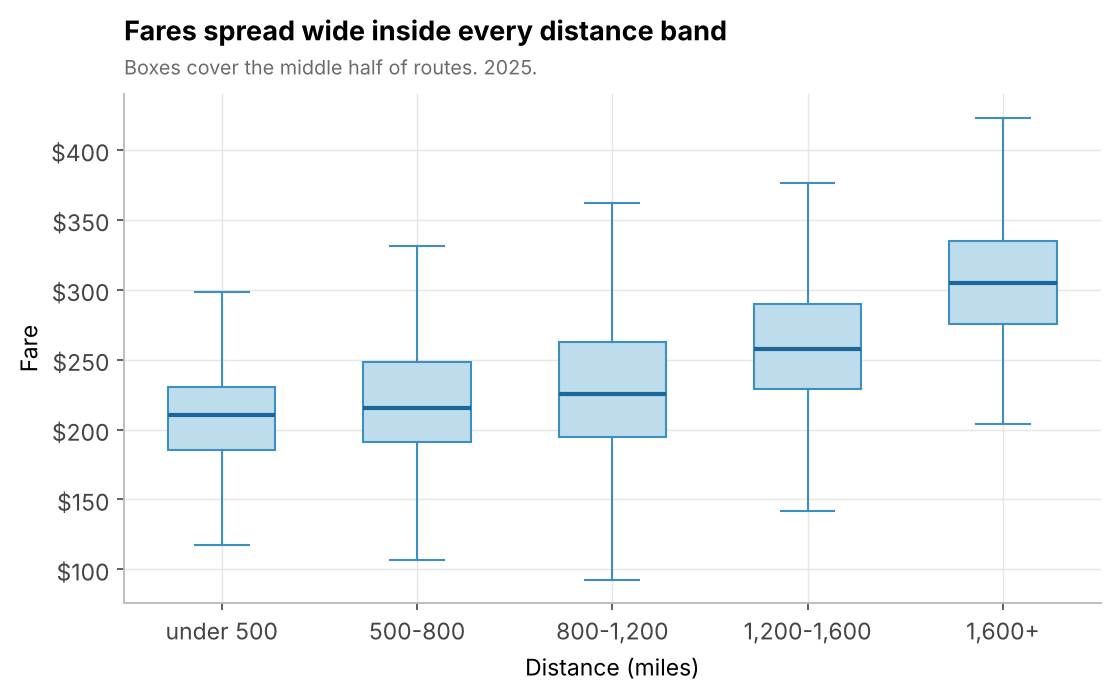

In [4]:
edges = [(0, 500), (500, 800), (800, 1200), (1200, 1600), (1600, 3000)]
labs  = ['under 500', '500-800', '800-1,200', '1,200-1,600', '1,600+']
data  = [r25[(r25.nsmiles >= a) & (r25.nsmiles < b)].fare.values for a, b in edges]

fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.boxplot(data, tick_labels=labs, patch_artist=True, widths=.55, showfliers=False,
           medianprops=dict(color=BLUE_D, lw=2),
           boxprops=dict(facecolor=BLUE_L, edgecolor=BLUE),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.set_xlabel('Distance (miles)'); ax.set_ylabel('Fare')
ax.yaxis.set_major_formatter(dollars)
title(ax, 'Fares spread wide inside every distance band',
      'Boxes cover the middle half of routes. 2025.')
save(fig, '02_distance_box')

## 3. Does a dominant airline charge more (H2)

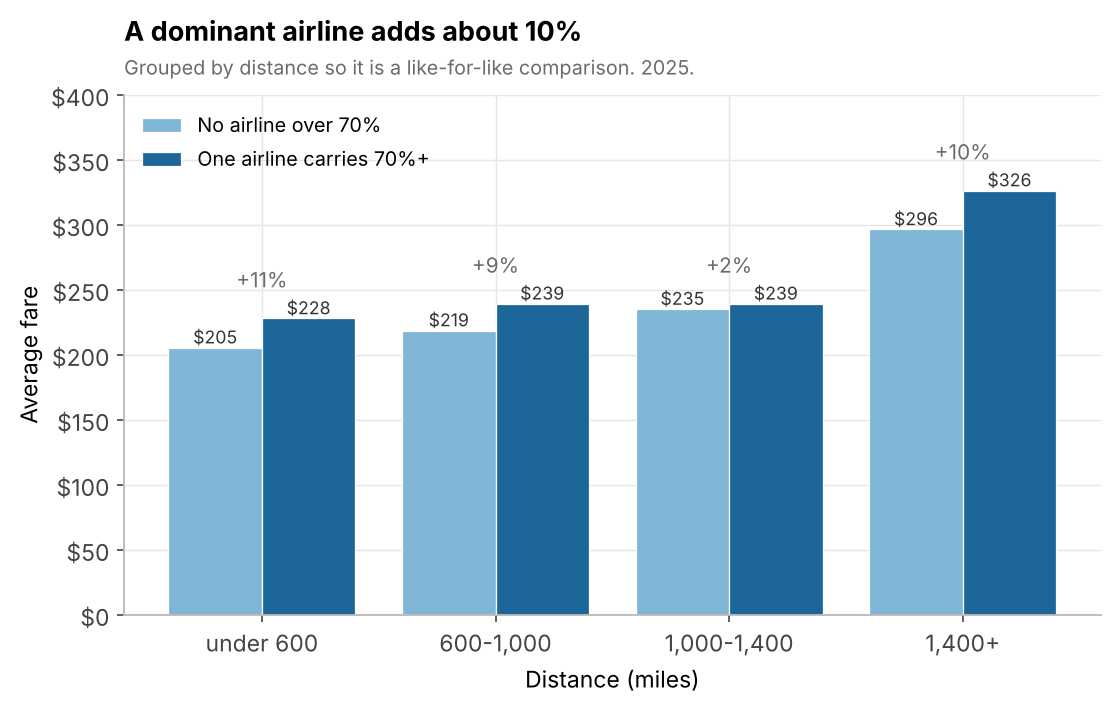

In [5]:
r25['conc'] = np.where(r25.large_ms >= .7, 'One airline carries 70%+', 'No airline over 70%')
p = r25.pivot_table(index='band4', columns='conc', values='fare', aggfunc='mean', observed=True)

fig, ax = plt.subplots(figsize=(8.4, 4.5))
bars(ax, list(p.index), ['No airline over 70%', 'One airline carries 70%+'],
     [p['No airline over 70%'].values, p['One airline carries 70%+'].values],
     [BLUE_M, BLUE_D])
for i, (a, b) in enumerate(zip(p['No airline over 70%'], p['One airline carries 70%+'])):
    ax.text(i, max(a, b) + 24, f'+{(b / a - 1) * 100:.0f}%', ha='center', fontsize=10, color=GREY)

ax.set_ylim(0, 400); ax.set_xlabel('Distance (miles)'); ax.set_ylabel('Average fare')
ax.yaxis.set_major_formatter(dollars); ax.legend(loc='upper left', fontsize=9.5)
title(ax, 'A dominant airline adds about 10%',
      'Grouped by distance so it is a like-for-like comparison. 2025.')
save(fig, '03_dominance')

## 4. Fare by route type (H3)

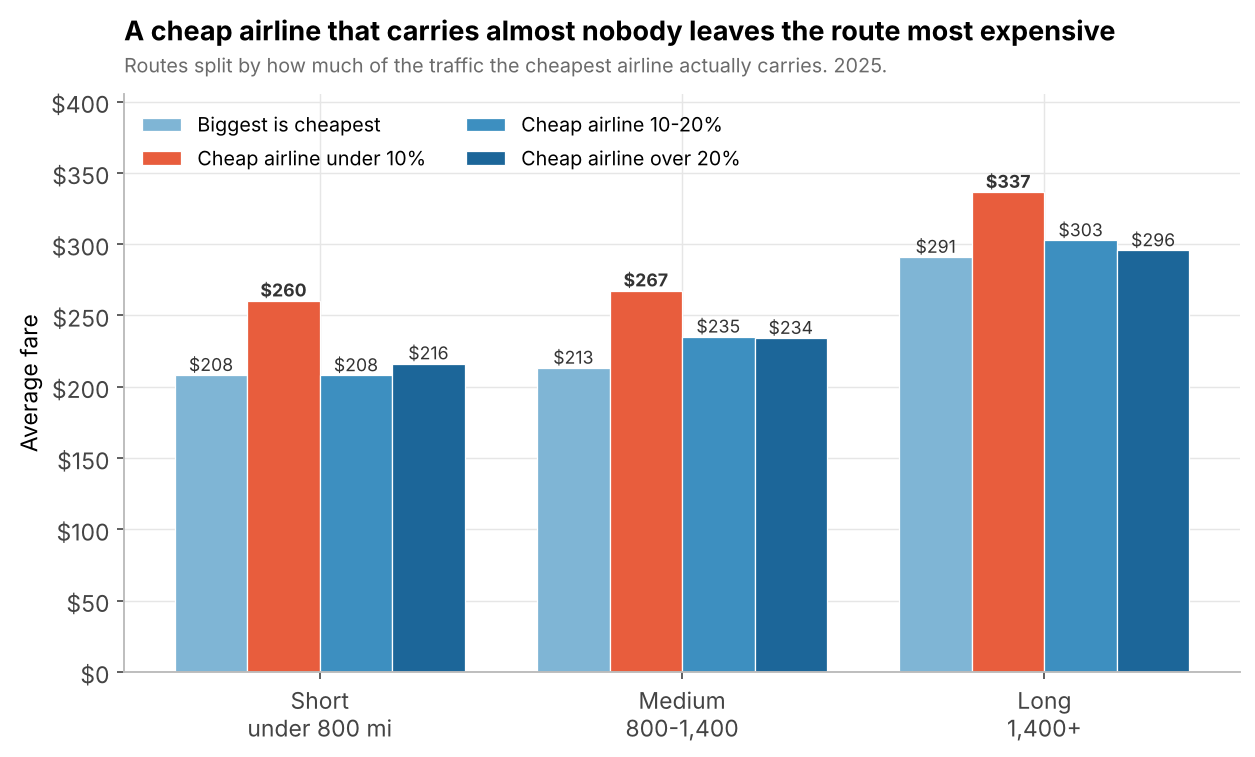

In [6]:
p5 = r25.pivot_table(index='band3', columns='route_type', values='fare',
                     aggfunc='mean', observed=True).reindex(columns=ORDER)

fig, ax = plt.subplots(figsize=(9.6, 5.0))
bars(ax, list(p5.index), ORDER, [p5[c].values for c in ORDER], FOUR,
     bold='Cheap airline under 10%')
ax.set_ylim(0, 405); ax.set_ylabel('Average fare')
ax.yaxis.set_major_formatter(dollars)
ax.legend(loc='upper left', fontsize=9.5, ncol=2)
title(ax, 'A cheap airline that carries almost nobody leaves the route most expensive',
      'Routes split by how much of the traffic the cheapest airline actually carries. 2025.')
save(fig, '04_route_types')

## 5. The discount nobody uses

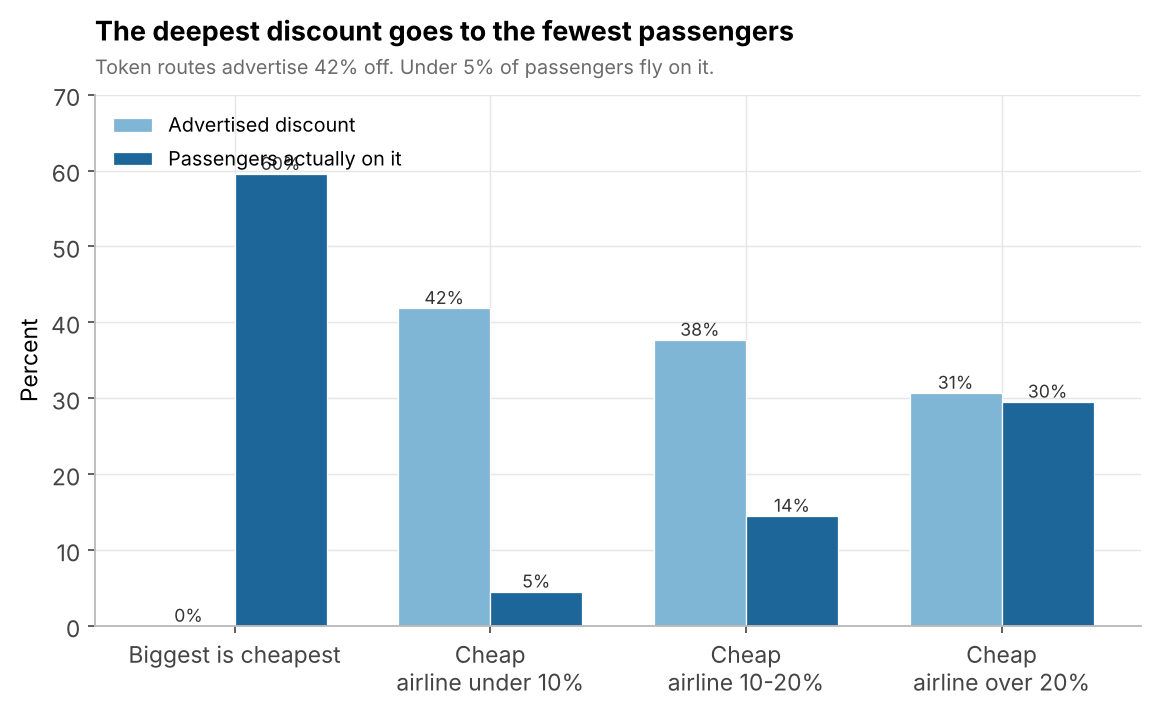

In [7]:
sub = r25[~r25['same']]
d2 = sub.groupby('route_type', observed=True).apply(
    lambda x: pd.Series({'discount': ((x.fare_lg - x.fare_low) / x.fare_lg * 100).mean(),
                         'share':    x.lf_ms.mean() * 100}), include_groups=False)
d2.loc['Biggest is cheapest'] = [0, r25[r25['same']].large_ms.mean() * 100]
d2 = d2.reindex(ORDER)

fig, ax = plt.subplots(figsize=(9.0, 4.6))
bars(ax, [c.replace(' airline', '\nairline') for c in ORDER],
     ['Advertised discount', 'Passengers actually on it'],
     [d2.discount.values, d2['share'].values], [BLUE_M, BLUE_D],
     fmt='{:.0f}%', width=.36)
ax.set_ylim(0, 70); ax.set_ylabel('Percent')
ax.legend(loc='upper left', fontsize=9.5)
title(ax, 'The deepest discount goes to the fewest passengers',
      'Token routes advertise 42% off. Under 5% of passengers fly on it.')
save(fig, '05_phantom_discount')

## 6. Thirty years of the same pattern

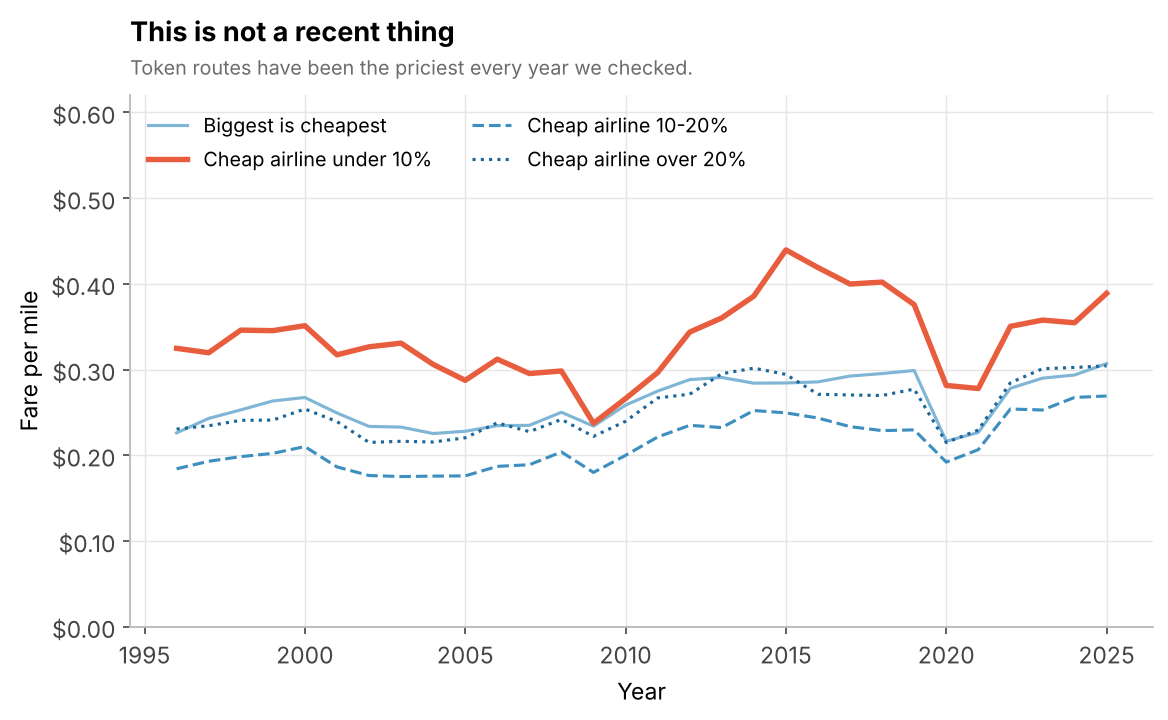

In [8]:
t = (df[df.Year.between(1996, 2025)]
     .groupby(['Year', 'route_type']).fare_per_mile.mean()
     .unstack().reindex(columns=ORDER))

fig, ax = plt.subplots(figsize=(8.8, 4.6))
for c, col, lw, ls in zip(ORDER, FOUR, [1.5, 2.6, 1.5, 1.5], ['-', '-', '--', ':']):
    ax.plot(t.index, t[c], ls, color=col, lw=lw, label=c)

ax.set_xlabel('Year'); ax.set_ylabel('Fare per mile'); ax.set_ylim(0, .62)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f'${v:.2f}'))
ax.legend(fontsize=9.5, ncol=2, loc='upper left')
title(ax, 'This is not a recent thing',
      'Token routes have been the priciest every year we checked.')
save(fig, '06_over_time')

## 7. Take distance out and compare the extremes

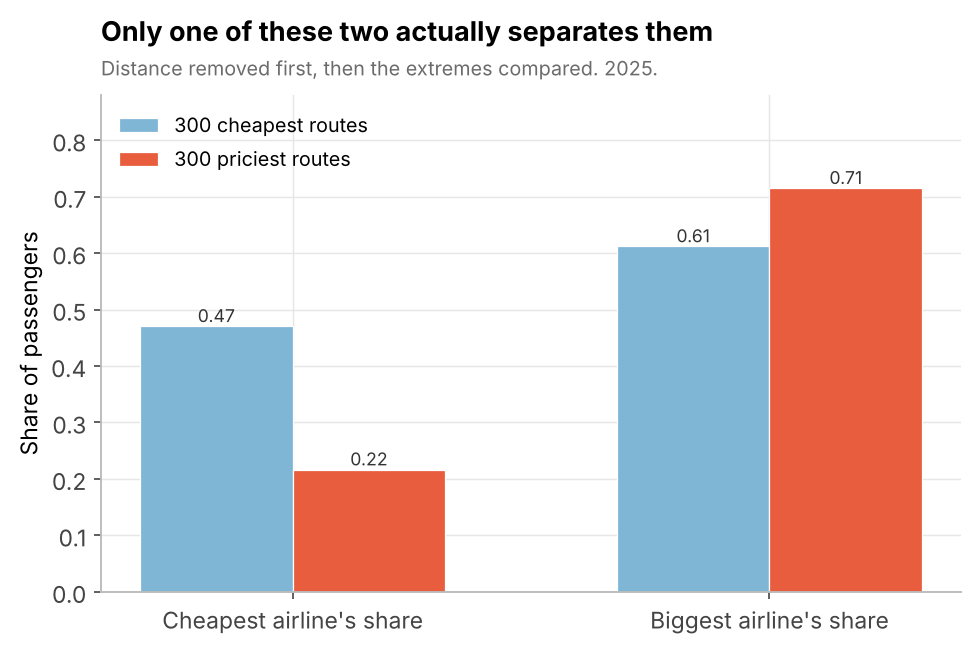

In [9]:
z  = np.polyfit(r25.nsmiles, r25.fare, 1)
rr = r25.assign(res=r25.fare - np.polyval(z, r25.nsmiles))
hi, lo = rr.nlargest(300, 'res'), rr.nsmallest(300, 'res')

fig, ax = plt.subplots(figsize=(7.4, 4.3))
bars(ax, ["Cheapest airline's share", "Biggest airline's share"],
     ['300 cheapest routes', '300 priciest routes'],
     [[lo.lf_ms.mean(), lo.large_ms.mean()],
      [hi.lf_ms.mean(), hi.large_ms.mean()]],
     [BLUE_M, ACCENT], fmt='{:.2f}', width=.32)
ax.set_ylim(0, .88); ax.set_ylabel('Share of passengers'); ax.legend(fontsize=9.5)
title(ax, 'Only one of these two actually separates them',
      'Distance removed first, then the extremes compared. 2025.')
save(fig, '07_residual')

## 8. How much the three factors explain

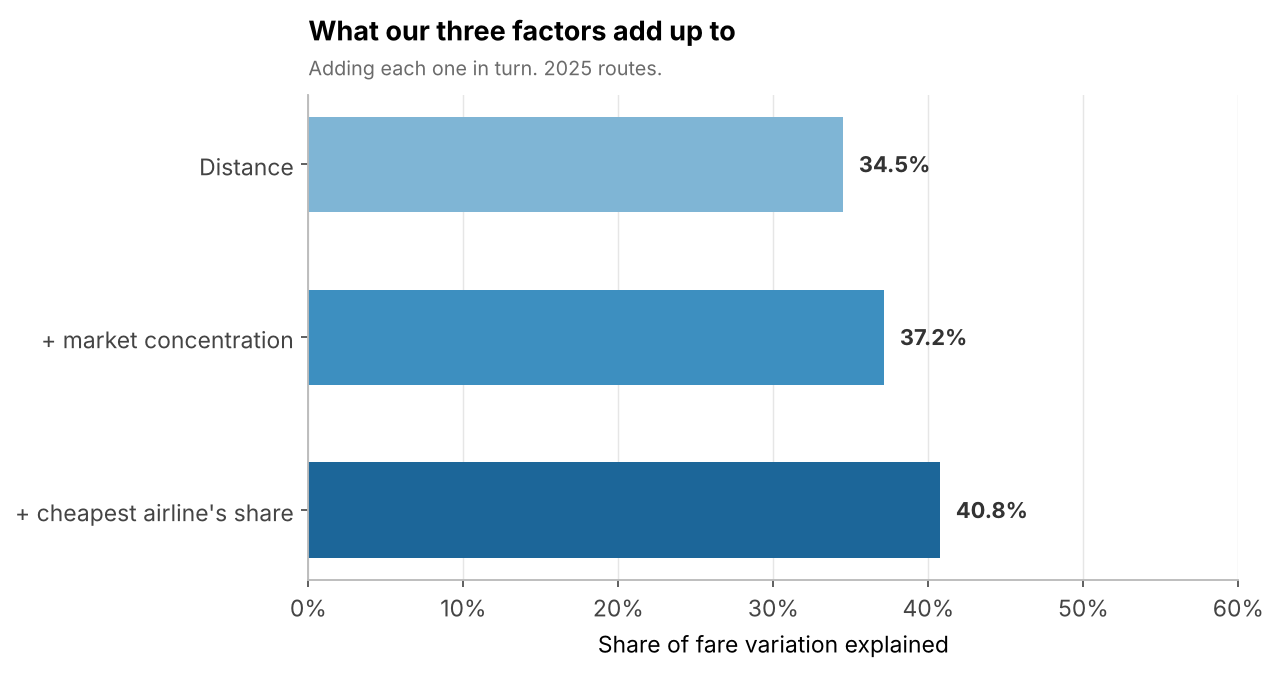

Distance                          34.5%
+ market concentration            37.2%
+ cheapest airline's share        40.8%


In [10]:
sub = r25.dropna(subset=['fare', 'nsmiles', 'large_ms', 'cheap_share'])
y = sub.fare.values

def r2(cols):
    X = np.c_[np.ones(len(sub)), sub[cols].values]
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    pred = X @ b
    return (1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()) * 100

steps = [('Distance',                   ['nsmiles']),
         ('+ market concentration',     ['nsmiles', 'large_ms']),
         ("+ cheapest airline's share", ['nsmiles', 'large_ms', 'cheap_share'])]
vals = [r2(c) for _, c in steps]

fig, ax = plt.subplots(figsize=(8.0, 4.2))
ax.barh([s[0] for s in steps], vals, color=[BLUE_M, BLUE, BLUE_D], height=.55)
for i, v in enumerate(vals):
    ax.text(v + 1, i, f'{v:.1f}%', va='center', fontsize=10.5, fontweight='bold', color='#333')
ax.set_xlim(0, 60); ax.invert_yaxis()
ax.set_xlabel('Share of fare variation explained')
ax.xaxis.set_major_formatter(pct); ax.grid(axis='y', visible=False)
title(ax, 'What our three factors add up to', 'Adding each one in turn. 2025 routes.')
save(fig, '08_explained')

for (lab, _), v in zip(steps, vals):
    print(f'{lab:32s} {v:5.1f}%')

## 9. Where token routes show up

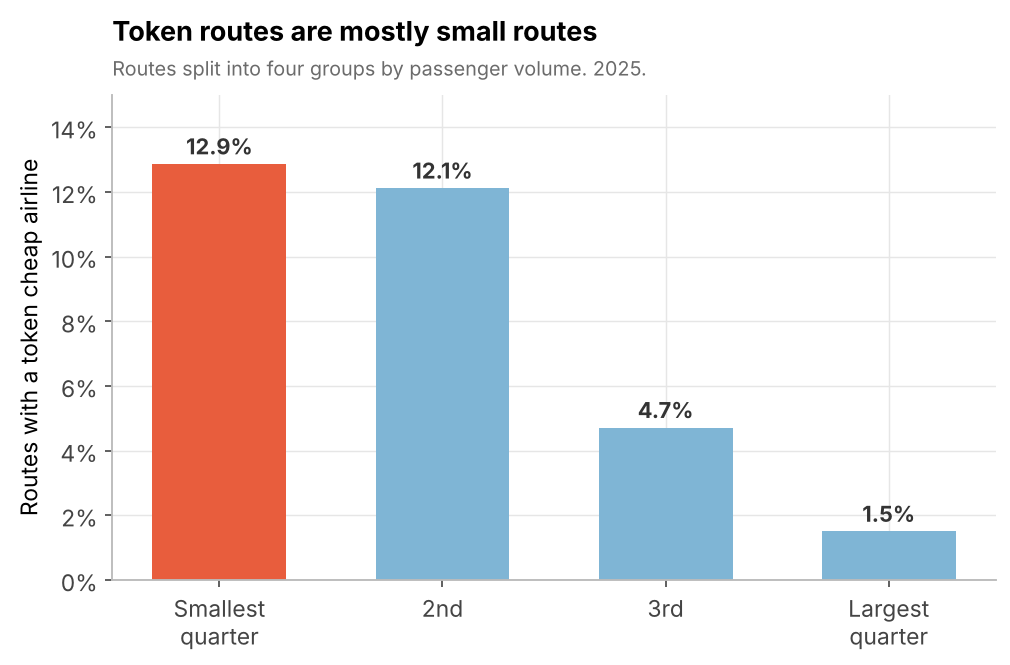

In [11]:
r25['tok'] = (~r25['same']) & (r25.lf_ms < .10)
q = pd.qcut(r25.passengers, 4, labels=['Smallest\nquarter', '2nd', '3rd', 'Largest\nquarter'])
rate = r25.groupby(q, observed=True).tok.mean() * 100

fig, ax = plt.subplots(figsize=(7.6, 4.2))
ax.bar(range(len(rate)), rate.values, width=.6,
       color=[ACCENT if v == rate.max() else BLUE_M for v in rate])
for i, v in enumerate(rate):
    ax.text(i, v + .3, f'{v:.1f}%', ha='center', fontsize=10.5, fontweight='bold', color='#333')
ax.set_xticks(range(len(rate))); ax.set_xticklabels(rate.index)
ax.set_ylabel('Routes with a token cheap airline'); ax.set_ylim(0, 15)
ax.yaxis.set_major_formatter(pct)
title(ax, 'Token routes are mostly small routes',
      'Routes split into four groups by passenger volume. 2025.')
save(fig, '09_token_by_size')

## 13. Tracking the same routes over time
Every other chart compares different routes. This one follows the same routes, which is closer to cause and effect.

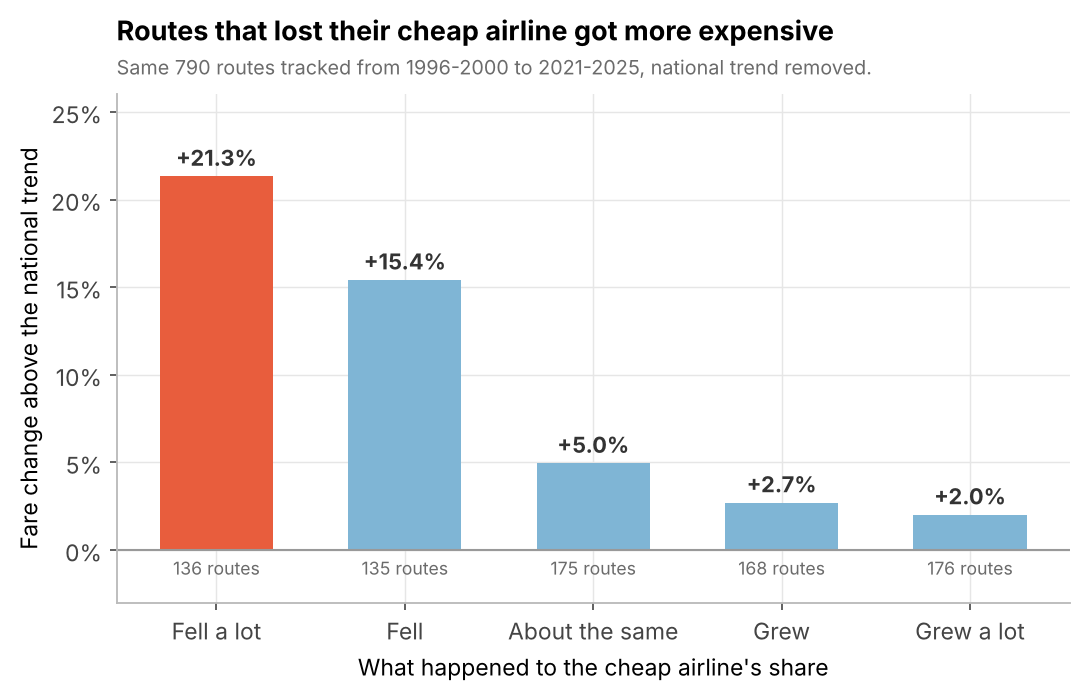

n=790  corr=-0.154  p=1.3e-05
                excess    n
dshare                     
Fell a lot        21.3  136
Fell              15.4  135
About the same     5.0  175
Grew               2.7  168
Grew a lot         2.0  176


In [12]:
df['route'] = df.city1 + ' <-> ' + df.city2
early = df[df.Year.between(1996, 2000)].groupby('route').agg(
    f0=('fare', 'mean'), c0=('cheap_share', 'mean'), n=('fare', 'size'))
late  = df[df.Year.between(2021, 2025)].groupby('route').agg(
    f1=('fare', 'mean'), c1=('cheap_share', 'mean'), n=('fare', 'size'))
m = early.join(late, how='inner', lsuffix='_a', rsuffix='_b')
m = m[(m.n_a >= 12) & (m.n_b >= 12)].copy()

# strip out the national trend so each route is compared to what everything else did
nat = (df[df.Year.between(2021, 2025)].fare.mean()
       / df[df.Year.between(1996, 2000)].fare.mean() - 1) * 100
m['excess'] = (m.f1 / m.f0 - 1) * 100 - nat
m['dshare'] = (m.c1 - m.c0) * 100

grp = pd.cut(m.dshare, [-100, -15, -5, 5, 15, 100],
             labels=['Fell a lot', 'Fell', 'About the same', 'Grew', 'Grew a lot'])
g = m.groupby(grp, observed=True).agg(excess=('excess', 'mean'), n=('excess', 'size'))

fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.bar(range(len(g)), g.excess.values, width=.6,
       color=[ACCENT if v == g.excess.max() else BLUE_M for v in g.excess])
for i, (v, n) in enumerate(zip(g.excess, g.n)):
    ax.text(i, v + .6, f'{v:+.1f}%', ha='center', fontsize=10.5, fontweight='bold', color='#333')
    ax.text(i, -1.4, f'{n} routes', ha='center', fontsize=8.5, color=GREY)
ax.axhline(0, color='#999', lw=1)
ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index)
ax.set_xlabel("What happened to the cheap airline's share")
ax.set_ylabel('Fare change above the national trend')
ax.set_ylim(-3, 26); ax.yaxis.set_major_formatter(pct)
title(ax, 'Routes that lost their cheap airline got more expensive',
      'Same 790 routes tracked from 1996-2000 to 2021-2025, national trend removed.')
save(fig, '13_longitudinal')

from scipy import stats
rho, pv = stats.pearsonr(m.dshare, m.excess)
print(f'n={len(m)}  corr={rho:.3f}  p={pv:.1e}')
print(g.round(1).to_string())

## Key numbers

In [13]:
from scipy import stats

band = r25[(r25.nsmiles >= 900) & (r25.nsmiles <= 1100)]
print(f'900-1,100 mi route-quarters: {len(band)} ({band.groupby(["city1", "city2"]).ngroups} routes), ${band.fare.min():.0f} to ${band.fare.max():.0f}, '
      f'{band.fare.max() / band.fare.min():.1f}x')
print(f'corr(distance, fare): {r25.nsmiles.corr(r25.fare):.3f}')

mid = r25[r25.nsmiles.between(600, 1400)]
tok = mid[mid.route_type == 'Cheap airline under 10%'].fare
oth = mid[mid.route_type != 'Cheap airline under 10%'].fare
t, p = stats.ttest_ind(tok, oth, equal_var=False)
d = (tok.mean() - oth.mean()) / np.sqrt((tok.var() + oth.var()) / 2)
print(f'token ${tok.mean():.0f} vs rest ${oth.mean():.0f}, '
      f'diff ${tok.mean() - oth.mean():.0f}, p={p:.1e}, d={d:.2f}')

ct = pd.crosstab(pd.qcut(r25.passengers, 4, labels=['Q1', 'Q2', 'Q3', 'Q4']), r25.tok)
chi2, pv, _, _ = stats.chi2_contingency(ct)
print(f'token rate Q1 {ct.loc["Q1", True] / ct.loc["Q1"].sum() * 100:.1f}% vs '
      f'Q4 {ct.loc["Q4", True] / ct.loc["Q4"].sum() * 100:.1f}%, chi2={chi2:.0f}, p={pv:.1e}')

900-1,100 mi route-quarters: 636 (185 routes), $86 to $377, 4.4x
corr(distance, fare): 0.587
token $268 vs rest $225, diff $43, p=1.0e-18, d=0.87
token rate Q1 12.9% vs Q4 1.5%, chi2=130, p=5.4e-28
